# TD · Nettoyage des données

**Module 13 · UE Ingénierie des Données · AMA** — mercredi 14 octobre 2026 · 3 h

On reprend le cours **sur le même fichier**, `commandes_brutes.csv` : les 50 312 lignes des commandes de septembre 2026 de la boutique en ligne. On exécute chaque étape, on regarde la sortie, on commente.

Après chaque étape, un **point 📊** montre ce qui a changé dans les indicateurs présentés à la direction (chiffre d'affaires, clients, satisfaction…) et combien des 8 tests qualité passent. À la fin, on nettoie le même fichier de **plusieurs façons**, et un tableau de bord montre comment chaque décision change l'histoire que l'on raconte.

| Partie | Slides du cours | Durée |
|---|---|---|
| 1 · Explorer | 8 à 11 | 20 min |
| 2 · Types et formats | 12 à 15 | 30 min |
| 3 · Doublons | 16 à 18 | 20 min |
| Pause | | 10 min |
| 4 · Valeurs aberrantes | 19 à 25 | 30 min |
| 5 · Valeurs manquantes | 26 à 30 | 25 min |
| 6 · Prouver la qualité et exporter | 31 à 33 | 15 min |
| 7 · Comparer les décisions, tableau de bord | — | 30 min |

💬 = une question pour la salle, avant de lancer la cellule suivante.

On importe les outils, on vérifie que le fichier est **identique, octet pour octet,** à celui du cours (empreinte SHA-256), puis on crée le **journal** des décisions et le **suivi** des indicateurs.

In [1]:
import io
import sys

import numpy as np
import pandas as pd

from tp_nettoyage.config import BRUT, ORACLE, RAPPORTS_DIR, SCENARIOS_DIR, SHA256_BRUT
from tp_nettoyage.outils import Journal, Suivi, empreinte

assert int(pd.__version__.split(".")[0]) >= 3, "pandas 3 est requis"
assert empreinte(BRUT) == SHA256_BRUT, "commandes_brutes.csv a été modifié"

TZ = "Africa/Porto-Novo"
DEBUT, FIN = pd.Timestamp("2026-09-01", tz=TZ), pd.Timestamp("2026-10-01", tz=TZ)
SCENARIOS_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

journal = Journal()
suivi = Suivi()
print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · fichier conforme")

Python 3.12.13 · pandas 3.0.6 · fichier conforme


`TZ` est le fuseau de Cotonou (UTC+1). `DEBUT` et `FIN` bornent le mois de septembre : on s'en servira pour vérifier les dates.

## 1. Explorer (slides 8 à 11)

Avant de corriger quoi que ce soit, on regarde.

### Charger sans se faire piéger (slide 8)

On choisit les types à la lecture : les identifiants restent du texte, et les sentinelles `"-"`, `"?"`, `"inconnu"` deviennent des valeurs manquantes. On garde une copie intacte, `brut`.

In [2]:
df = pd.read_csv(
    BRUT,
    dtype={"commande_id": str, "client_id": str, "telephone": str},
    na_values=["-", "?", "inconnu"],
)
brut = df.copy()
df.shape

(50312, 17)

50 312 lignes pour 50 000 commandes attendues : il y a déjà 312 lignes de trop. Le brut est sacré : on ne le modifiera jamais, on travaille sur des copies.

Sans `dtype`, pandas devine… et se trompe :

In [3]:
pd.read_csv(io.StringIO("telephone\n0197000003\n"))

,telephone
0,197000003


Le zéro a disparu : un numéro de téléphone n'est pas un nombre.

### Les 10 commandes du premier contact (slide 9)

In [4]:
df.sample(5, random_state=0)

,commande_id,date_commande,client_id,telephone,email,ville,categorie,quantite,prix_unitaire_fcfa,montant_fcfa,moyen_paiement,statut,note_client,date_livraison,poids_kg,code_promo,maj_le
25728,CMD0032716,2026-09-20 14:12:48,CL008032,0194202439,NaN,Bohicon,Téléphonie,1,133000,133000,Paiement à la livraison,livrée,4.0,2026-09-28 06:07:09,0.59,NaN,2026-09-28 06:16:18
16466,CMD0038283,2026-09-23 23:21:18,CL015471,+229 01 94 85 86 68,aicha.zinsou47@example.com,Porto-Novo,Mode,1,6500,6500,Mobile Money,annulée,NaN,NaN,1.21,NaN,2026-09-24 01:14:05
35498,CMD0006496,2026-09-04 19:23:57,CL017774,0158831971,rachida.adjovi22@example.com,COTONOU,Maison,2,24 500,49000,Mobile Money,livrée,1.0,2026-09-07 06:29:07,10.79,NaN,2026-09-07 07:29:53
30127,CMD0031052,2026-09-19 13:50:37,CL005784,0156588044,mathieu.akpovi60@example.com,Cotonou,Beauté,3,4000,12000,Mobile Money,annulée,NaN,NaN,0.24,NaN,2026-09-19 14:06:35
10371,CMD0049159,2026-09-30 10:20:17,CL009428,0162355363,yao.gbaguidi18@example.com,Abomey-Calavi,Téléphonie,3,133500,400500,Mobile Money,livrée,2.0,2026-10-01 23:47:14,0.26,NaN,2026-10-02 00:48:17


Cinq lignes au hasard suffisent : un téléphone écrit « +229 01 94 85 86 68 », une ville en majuscules (« COTONOU »), un prix avec une espace (« 24 500 »). `sample()` tire dans tout le fichier, là où `head()` ne montre que le début.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50312 entries, 0 to 50311
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   commande_id         50312 non-null  str    
 1   date_commande       50312 non-null  str    
 2   client_id           50312 non-null  str    
 3   telephone           48806 non-null  str    
 4   email               39426 non-null  str    
 5   ville               50207 non-null  str    
 6   categorie           50312 non-null  str    
 7   quantite            50312 non-null  int64  
 8   prix_unitaire_fcfa  50312 non-null  str    
 9   montant_fcfa        50312 non-null  int64  
 10  moyen_paiement      50072 non-null  str    
 11  statut              50312 non-null  str    
 12  note_client         31790 non-null  float64
 13  date_livraison      42746 non-null  str    
 14  poids_kg            48797 non-null  str    
 15  code_promo          4263 non-null   str    
 16  maj_le         

14 colonnes sur 17 sont du texte (`str`), dont le prix, le poids et les trois dates.

In [6]:
df[["ville", "statut", "moyen_paiement", "categorie"]].nunique()

ville             25
statut            14
moyen_paiement    15
categorie          9
dtype: int64

25 écritures pour 5 villes, 14 pour 4 statuts, 15 pour 3 moyens de paiement, 9 pour 6 catégories.

In [7]:
df["ville"].value_counts(dropna=False)

ville
Cotonou          19157
Abomey-Calavi    10638
Porto-Novo        6432
Parakou           3398
Bohicon           3027
 Cotonou           608
Ctn                598
Cotonou            575
cotonou            565
COTONOU            552
Cotonu             531
Abomey Calavi      392
abomey-calavi      389
Abomey-calavi      371
Calavi             364
ABOMEY-CALAVI      363
Porto-novo         313
Porto Novo         282
PORTO-NOVO         273
porto-novo         272
bohicon            257
BOHICON            254
PARAKOU            208
Parakou            198
parakou            190
NaN                105
Name: count, dtype: int64

« Cotonou » apparaît plusieurs fois : avec une espace avant, une espace après, en majuscules, en abrégé (« Ctn »). À l'œil, « Cotonou » et « Cotonou␣ » sont identiques.

In [8]:
print(df.duplicated().sum(), "lignes identiques ·", df["commande_id"].duplicated().sum(), "identifiants répétés")

212 lignes identiques · 312 identifiants répétés


212 lignes en double exact, et 312 identifiants répétés : 100 commandes apparaissent en plusieurs versions.

### Lire un `describe()` comme un détective (slide 10)

💬 Trois colonnes, huit lignes de chiffres : combien d'indices voyez-vous ?

In [9]:
df.describe().round(1)

,quantite,montant_fcfa,note_client
count,50312.0,50312.0,31790.0
mean,1.8,43819.6,4.2
std,6.8,108825.0,1.5
min,-5.0,-1368000.0,0.0
25%,1.0,9000.0,4.0
50%,1.0,20000.0,4.0
75%,2.0,49000.0,5.0
max,500.0,9750000.0,50.0


In [10]:
df.describe(exclude="number").T

,count,unique,top,freq
commande_id,50312,50000,CMD0000086,2
date_commande,50312,49480,2026-09-28 03:26:12,4
client_id,50312,18330,CL010266,10
telephone,48806,27881,97,274
email,39426,14057,codjo.sossa57@example.com,16
ville,50207,25,Cotonou,19157
categorie,50312,9,Mode,12669
prix_unitaire_fcfa,50312,1307,2500,1226
moyen_paiement,50072,15,Mobile Money,24138
statut,50312,14,livrée,40036


Les indices :
1. 3 colonnes numériques sur 17 : le prix, le poids et les dates sont lus comme du texte.
2. `note_client` : 31 790 valeurs sur 50 312, soit 36,8 % de manquants.
3. Quantité minimale −5 : un retour, ou une erreur de signe ?
4. Quantité maximale 500, alors que 75 % des commandes ont au plus 2 articles.
5. Montant minimal −1 368 000 : un remboursement ?
6. Montant moyen 43 820, plus de 2 fois la médiane (20 000) : distribution très asymétrique.
7. Notes de 0 à 50 sur une échelle de 1 à 5.
8. Date de livraison la plus fréquente : 1900-01-01, 53 fois : une date bidon.
9. 50 000 identifiants pour 50 312 lignes, et « 97 » est le téléphone le plus fréquent.

### Le profil de chaque colonne (slide 11)

Une petite fonction donne la carte d'identité de chaque colonne.

In [11]:
def profil(df):
    return pd.DataFrame({
        "type":        df.dtypes.astype(str),
        "manquants_%": df.isna().mean().mul(100).round(1),
        "distincts":   df.nunique(),
        "exemples":    pd.Series({c: df[c].dropna().unique()[:3].tolist() for c in df}),
    }).sort_values("manquants_%", ascending=False)


profil(df)

,type,manquants_%,distincts,exemples
code_promo,str,91.5,3,"[RENTREE26, FLASH09, BIENVENUE10]"
note_client,float64,36.8,9,"[4.0, 5.0, 1.0]"
email,str,21.6,14057,"[aicha.adjovi41@example.com, aicha.zinsou71@ex..."
date_livraison,str,15.0,42159,"[2026-09-08 01:52:08, 2026-09-10 11:28:14, 202..."
poids_kg,str,3.0,3235,"[0,27, 0.17, 0.84]"
telephone,str,3.0,27881,"[0197127088, 90 84 53 91, 0155227577]"
moyen_paiement,str,0.5,15,"[Mobile Money, Paiement à la livraison, Mobile..."
ville,str,0.2,25,"[Cotonou, Parakou, ABOMEY-CALAVI]"
commande_id,str,0.0,50000,"[CMD0009743, CMD0014400, CMD0045672]"
prix_unitaire_fcfa,str,0.0,1307,"[7500, 8500, 4500]"


27 881 téléphones pour 18 330 clients : un même numéro est écrit de plusieurs façons. Et un prix en texte ne se calcule pas :

In [12]:
try:
    brut["prix_unitaire_fcfa"].mean()
except TypeError as e:
    print("TypeError :", e)

TypeError : Cannot perform reduction 'mean' with string dtype


### 📊 Point 0 · le brut

`suivi.point` calcule les indicateurs que l'on présenterait à la direction et les 8 tests qualité de la slide 31. On le relancera après chaque étape pour voir ce qui change.

In [13]:
suivi.point("0 · brut", brut)

📊 Point « 0 · brut » · tests qualité 1 / 8 · volumétrie ✅
   Tests en échec : commande_id unique · statut connu · ville du référentiel · note entre 1 et 5 · livraison après commande · montant = quantité × prix · commandes de septembre


,maintenant · 0 · brut
Lignes,50 312
Commandes livrées,40 036
Chiffre d'affaires,"1 856,8 M FCFA"
Panier moyen,46 378 FCFA
Prix unitaire moyen,incalculable
Clients actifs,17 198
Clients comptés par téléphone,24 276
Taux de réachat,"68,9 %"
Rétention de la semaine 1,incalculable
Note moyenne,"4,16 / 5"


Quatre indicateurs sont incalculables (prix moyen, rétention, délai, meilleur jour) et un seul test sur 8 passe. Pourtant, le chiffre d'affaires s'affiche sans broncher : 1 856,8 M FCFA. 💬 Faut-il lui faire confiance ?

## 2. Types et formats (slides 12 à 15)

Le bon type est une validation gratuite : ce qui n'y entre pas est une anomalie. Chaque étape devient une petite fonction : un DataFrame entre, un DataFrame sort, et chaque décision est inscrite au journal.

### Les prix : « coerce, puis compte » (slide 13)

Premier essai : on retire les espaces (`\s`) et « FCFA », puis on convertit. On compte les prix **perdus** : présents avant, NaN après.

In [56]:
s = brut["prix_unitaire_fcfa"]
naif = pd.to_numeric(s.str.replace(r"\s|FCFA", "", regex=True), errors="coerce")
perdus = naif.isna() & s.notna()
print(perdus.sum(), "prix perdus :", s[perdus].unique()[:3].tolist())

2052 prix perdus : ['144\xa0000', '16\xa0000', '25\xa0500']


2 052 prix perdus, sans la moindre erreur ! Le `\xa0` est une **espace insécable** (celle des exports français). Les chaînes de pandas 3 passent par le moteur de regex de PyArrow, où `\s` ne reconnaît que les espaces ordinaires. Seul le compteur l'a révélé.

On retire donc **tout ce qui n'est pas un chiffre** (`\D`), et on vérifie qu'aucun prix n'est perdu :

In [15]:
def convertir_prix(df, journal):
    df = df.copy()
    s = df["prix_unitaire_fcfa"]
    journal.tracer("types", "prix stocké en texte (espaces, « FCFA »)", "prix_unitaire_fcfa",
                   s.str.contains(r"\D", na=False), "convertir en Int64 (\\D retiré)")
    prix = pd.to_numeric(s.str.replace(r"\D", "", regex=True), errors="coerce")
    perdus = prix.isna() & s.notna()
    assert perdus.sum() == 0, f"{perdus.sum()} prix perdus"
    df["prix_unitaire_fcfa"] = prix.astype("Int64")
    return df


def convertir_poids(df, journal):
    df = df.copy()
    w = df["poids_kg"]
    journal.tracer("types", "poids avec virgule décimale", "poids_kg", w.str.contains(",", na=False), "convertir en float64")
    df["poids_kg"] = pd.to_numeric(w.str.replace(",", ".", regex=False), errors="coerce")
    return df


essai = convertir_poids(convertir_prix(brut, Journal()), Journal())
essai[["prix_unitaire_fcfa", "poids_kg"]].dtypes

prix_unitaire_fcfa      Int64
poids_kg              float64
dtype: object

Le prix est en `Int64` (un entier qui accepte les manquants), le poids en `float64` : « 0,27 » est devenu 0.27. Aucune valeur perdue.

### Les dates : formats, fenêtre, fuseau (slide 14)

Les dates arrivent en 4 formats (ISO, ISO « …T…Z », jj/mm, mm/jj), en UTC. « 09/05/2026 » se lit 9 mai ou 5 septembre : comme le fichier ne contient que septembre, **la fenêtre tranche**. On exprime ensuite tout dans le fuseau de Cotonou.

In [16]:
def convertir_dates(df, journal, fuseau=TZ):
    df = df.copy()
    s = df["date_commande"]
    iso = pd.to_datetime(s, format="ISO8601", utc=True, errors="coerce")
    fr = pd.to_datetime(s, format="%d/%m/%Y %H:%M", errors="coerce").dt.tz_localize("UTC")
    us = pd.to_datetime(s, format="%m/%d/%Y %H:%M", errors="coerce").dt.tz_localize("UTC")
    d, us = iso.fillna(fr).dt.tz_convert(TZ), us.dt.tz_convert(TZ)

    def septembre(x):
        return x.between(DEBUT, FIN, inclusive="left")

    reprendre = ~septembre(d) & septembre(us)
    journal.tracer("types", "date au format américain mm/jj", "date_commande", reprendre, "relire en mm/jj (fenêtre de septembre)")
    d = d.mask(reprendre, us)
    assert (d.isna() & s.notna()).sum() == 0, "dates illisibles"
    assert (d.notna() & ~septembre(d)).sum() == 0, "dates hors de septembre"
    df["date_commande"] = d.dt.tz_convert(fuseau)
    for col in ["date_livraison", "maj_le"]:
        df[col] = pd.to_datetime(df[col], format="ISO8601", utc=True, errors="coerce").dt.tz_convert(fuseau)
    return df


j = Journal()
essai = convertir_dates(brut, j)
j.table()

,étape,règle,colonne,lignes,décision
0,types,date au format américain mm/jj,date_commande,545,relire en mm/jj (fenêtre de septembre)


545 dates américaines ont été relues en mm/jj, aucune n'est illisible ni hors de septembre. 💬 Et si on était resté en UTC ?

In [17]:
d = essai["date_commande"]
int((d.dt.date != d.dt.tz_convert("UTC").dt.date).sum())

2045

2 045 commandes, passées entre minuit et 1 h à Cotonou, auraient été rangées la veille : tous les indicateurs par jour seraient décalés.

On enchaîne les trois conversions dans une seule étape, et on fait le point.

In [18]:
def etape_types(df, journal, fuseau=TZ):
    df = convertir_prix(df, journal)
    df = convertir_poids(df, journal)
    return convertir_dates(df, journal, fuseau)


df = etape_types(brut, journal)
suivi.point("1 · types convertis", df)

📊 Point « 1 · types convertis » · tests qualité 2 / 8 · volumétrie ✅
   Tests en échec : commande_id unique · statut connu · ville du référentiel · note entre 1 et 5 · livraison après commande · montant = quantité × prix


,début · 0 · brut,maintenant · 1 · types convertis,écart / précédent
Lignes,50 312,50 312,=
Commandes livrées,40 036,40 036,=
Chiffre d'affaires,"1 856,8 M FCFA","1 856,8 M FCFA",=
Panier moyen,46 378 FCFA,46 378 FCFA,=
Prix unitaire moyen,incalculable,29 120 FCFA,devient calculable
Clients actifs,17 198,17 198,=
Clients comptés par téléphone,24 276,24 276,=
Taux de réachat,"68,9 %","68,9 %",=
Rétention de la semaine 1,incalculable,"78,9 %",devient calculable
Note moyenne,"4,16 / 5","4,16 / 5",=


Le prix moyen, la rétention, le délai et le meilleur jour deviennent calculables. 💬 Mais un délai moyen de livraison de −55,4 jours ? Ce sont les livraisons datées de 1900 et celles antérieures à la commande : le bon type ne suffit pas, on les traitera en partie 4. Les tests passent de 1 à 2 sur 8.

### Les catégories : un référentiel (slide 15)

On liste ce qui existe (`value_counts`), on écrit le référentiel, et tout ce qui n'y entre pas est montré au métier.

In [19]:
df["moyen_paiement"].str.strip().str.lower().value_counts()

moyen_paiement
mobile money               26197
paiement à la livraison    15412
carte bancaire              4656
momo                        1340
a la livraison               532
espèces                      521
à la livraison               514
cash                         489
carte                        211
cb                           200
Name: count, dtype: int64

In [20]:
def normaliser(s, referentiel):
    cle = s.str.strip().str.lower()
    propre = cle.map(referentiel)
    inconnus = cle[propre.isna() & cle.notna()].value_counts()
    return propre, inconnus


VILLES = {"cotonou": "Cotonou", "ctn": "Cotonou", "cotonu": "Cotonou",
          "abomey-calavi": "Abomey-Calavi", "abomey calavi": "Abomey-Calavi", "calavi": "Abomey-Calavi",
          "porto-novo": "Porto-Novo", "porto novo": "Porto-Novo", "parakou": "Parakou", "bohicon": "Bohicon"}
PAIEMENTS = {"mobile money": "Mobile Money", "momo": "Mobile Money",
             "paiement à la livraison": "Paiement à la livraison", "à la livraison": "Paiement à la livraison",
             "a la livraison": "Paiement à la livraison", "cash": "Paiement à la livraison",
             "espèces": "Paiement à la livraison",
             "carte bancaire": "Carte bancaire", "carte": "Carte bancaire", "cb": "Carte bancaire"}
STATUTS = {"livrée": "livrée", "livree": "livrée", "annulée": "annulée", "annulee": "annulée",
           "en cours": "en cours", "en_cours": "en cours", "retournée": "retournée", "retournee": "retournée"}

for col, ref in [("ville", VILLES), ("moyen_paiement", PAIEMENTS), ("statut", STATUTS)]:
    propre, inconnus = normaliser(df[col], ref)
    print(f"{col} : {df[col].nunique()} → {propre.nunique()} valeurs, {len(inconnus)} inconnue(s)")

ville : 25 → 5 valeurs, 0 inconnue(s)
moyen_paiement : 15 → 3 valeurs, 0 inconnue(s)
statut : 14 → 4 valeurs, 0 inconnue(s)


25 → 5 villes, 15 → 3 paiements, 14 → 4 statuts, et aucune écriture inconnue.

### L'encodage, les téléphones, les e-mails (slides 11 et 15)

« TÃ©lÃ©phonie » est du texte UTF-8 relu comme du cp1252 : on refait le chemin à l'envers.

In [21]:
def reparer_encodage(s):
    s = s.copy()
    casse = s.str.contains("Ã", na=False)
    s.loc[casse] = s.loc[casse].str.encode("cp1252").str.decode("utf-8")
    return s


reparer_encodage(df["categorie"]).value_counts()

categorie
Mode          12669
Beauté         7595
Épicerie       7577
Téléphonie     7523
Maison         7493
Audio          7455
Name: count, dtype: int64

9 catégories redeviennent 6 (351 valeurs réparées). Pour les téléphones, une expression régulière : chiffres seuls, sans l'indicatif 229, le zéro mangé par un tableur remis, l'ancien numéro à 8 chiffres complété.

In [22]:
def normaliser_tel(s):
    d = s.str.replace(r"\D", "", regex=True)
    d = d.str.replace(r"^(?:00)?229(?=\d{8}$|\d{10}$)", "", regex=True)
    d = d.mask(d.str.len() == 9, "0" + d)
    d = d.mask(d.str.len() == 8, "01" + d)
    return d.where(d.str.fullmatch(r"01\d{8}", na=False))


exemples = pd.Series(["97 12 34 57", "0022996554433", "+229 0161000000", "197000003", "+33 6 12 34 56 78"], dtype="str")
pd.DataFrame({"brut": exemples, "normalisé": normaliser_tel(exemples)})

,brut,normalisé
0,97 12 34 57,0197123457
1,0022996554433,0196554433
2,+229 0161000000,0161000000
3,197000003,0197000003
4,+33 6 12 34 56 78,NaN


Le numéro étranger devient NaN : on ne l'invente pas, on le signale. Les e-mails : espaces retirés, minuscules, puis un motif simple.

In [23]:
def nettoyer_email(s):
    email = s.str.strip().str.lower()
    ok = email.str.fullmatch(r"[\w.+-]+@[\w-]+\.[\w.]+", na=False)
    return email.where(ok)


int((nettoyer_email(df["email"]).isna() & df["email"].notna()).sum())

221

221 adresses invalides (le « @ » remplacé par un point) passent en NaN. On rassemble tout dans une étape, qui trace chaque règle au journal.

In [24]:
def etape_formats(df, journal):
    df = df.copy()
    for col, ref, nom in [("ville", VILLES, "villes"), ("moyen_paiement", PAIEMENTS, "paiements"), ("statut", STATUTS, "statuts")]:
        propre, inconnus = normaliser(df[col], ref)
        assert inconnus.empty, f"{col} : valeurs hors référentiel {inconnus.to_dict()}"
        journal.tracer("types", f"{nom} hors référentiel", col, propre.notna() & (propre != df[col]), "ramener au référentiel")
        df[col] = propre
    df["ville"] = df["ville"].astype("category")
    categorie = reparer_encodage(df["categorie"])
    journal.tracer("types", "catégorie mal encodée (« TÃ©lÃ©phonie »)", "categorie", categorie != df["categorie"],
                   "encode cp1252 / decode utf-8")
    df["categorie"] = categorie.astype("category")
    tel = normaliser_tel(df["telephone"])
    journal.tracer("types", "téléphone hors format 01XXXXXXXX", "telephone", tel.notna() & (tel != df["telephone"]), "reformater")
    journal.tracer("types", "téléphone invalide (« 97 », étranger, 0000000000)", "telephone", tel.isna() & df["telephone"].notna(), "NaN")
    df["telephone"] = tel
    email = nettoyer_email(df["email"])
    journal.tracer("types", "e-mail invalide", "email", email.isna() & df["email"].notna(), "NaN")
    df["email"] = email
    return df


df = etape_formats(df, journal)
suivi.point("2 · formats normalisés", df)

📊 Point « 2 · formats normalisés » · tests qualité 4 / 8 · volumétrie ✅
   Tests en échec : commande_id unique · note entre 1 et 5 · livraison après commande · montant = quantité × prix


,début · 0 · brut,précédent · 1 · types convertis,maintenant · 2 · formats normalisés,écart / précédent
Lignes,50 312,50 312,50 312,=
Commandes livrées,40 036,40 036,41 292,"+3,1 %"
Chiffre d'affaires,"1 856,8 M FCFA","1 856,8 M FCFA","1 920,1 M FCFA","+3,4 %"
Panier moyen,46 378 FCFA,46 378 FCFA,46 500 FCFA,"+0,3 %"
Prix unitaire moyen,incalculable,29 120 FCFA,29 120 FCFA,=
Clients actifs,17 198,17 198,17 379,"+1,1 %"
Clients comptés par téléphone,24 276,24 276,17 117,"−29,5 %"
Taux de réachat,"68,9 %","68,9 %","70,1 %","+1,6 %"
Rétention de la semaine 1,incalculable,"78,9 %","79,9 %","+1,2 %"
Note moyenne,"4,16 / 5","4,16 / 5","4,16 / 5",=


💬 Aucune ligne n'a été supprimée. Pourquoi les indicateurs bougent-ils autant ?

- La part de Mobile Money passe de 47,98 % à 54,73 % : « MoMo » et « momo » comptent enfin.
- Cotonou passe de 38,58 % à 45,19 % du CA : « Ctn » et « Cotonou␣ » sont rattachés à Cotonou.
- Les clients comptés par téléphone tombent de 24 276 à 17 117 : un même numéro écrit de plusieurs façons comptait plusieurs fois.
- Le CA monte à 1 920,1 M FCFA : les commandes « Livree » comptent maintenant comme livrées.

## 3. Doublons (slides 16 à 18)

Un doublon n'est pas forcément une ligne identique : c'est une même réalité comptée deux fois.

In [25]:
df.loc[df["commande_id"] == "CMD0001702", ["commande_id", "statut", "date_livraison", "maj_le"]]

,commande_id,statut,date_livraison,maj_le
18923,CMD0001702,livrée,2026-09-04 03:40:33+01:00,2026-09-04 04:38:03+01:00
46688,CMD0001702,en cours,NaT,2026-09-02 00:42:50+01:00


La même commande, « en cours » le 2 septembre puis « livrée » le 4 : deux exports successifs. On supprime les doublons exacts, puis on garde la version la plus récente (`maj_le`), et on **prouve** que la clé est unique.

In [26]:
def dedoublonner(df, journal):
    exacts = df.duplicated()
    journal.tracer("doublons", "lignes identiques", "toutes", exacts, "supprimer")
    df = df.drop_duplicates()
    versions = df.duplicated("commande_id", keep=False)
    journal.tracer("doublons", "même commande, plusieurs versions", "commande_id",
                   df.loc[versions, "commande_id"].nunique(), "garder la plus récente (maj_le)")
    df = df.sort_values("maj_le").drop_duplicates("commande_id", keep="last")
    assert df["commande_id"].is_unique, "commande_id n'est pas unique"
    return df


len(dedoublonner(df, Journal()))

50000

50 000 commandes, une ligne chacune. Restent les doublons **métier** : même client, même panier, quelques secondes d'écart, deux identifiants (un double clic sur « Payer »). On ne les supprime pas en silence : on les **marque** pour les rembourser, et ils sortent du chiffre d'affaires.

In [27]:
def marquer_doubles_clics(df, journal):
    df = df.sort_values(["client_id", "date_commande"])
    cols = ["montant_fcfa", "categorie", "quantite"]
    prec = df.groupby("client_id")[cols + ["date_commande"]].shift()
    ecart_s = (df["date_commande"] - prec["date_commande"]).dt.total_seconds()
    df["double_clic"] = (ecart_s < 10) & df[cols].eq(prec[cols]).all(axis=1)
    journal.tracer("doublons", "double clic (même client, même panier, < 10 s)", "commande_id",
                   df["double_clic"], "garder + drapeau double_clic, exclure du CA")
    return df.sort_values("date_commande").reset_index(drop=True)


int(marquer_doubles_clics(dedoublonner(df, Journal()), Journal())["double_clic"].sum())

54

54 doubles clics. 💬 La quatrième sorte de doublon naît d'une jointure : une commande payée en deux fois, et la jointure multiplie les lignes.

In [28]:
paiements = pd.DataFrame({
    "commande_id": ["CMD0001702", "CMD0004242", "CMD0031415", "CMD0031415"],
    "montant_paye_fcfa": [2500, 12500, 30000, 16000],
})
commandes = dedoublonner(df, Journal())[["commande_id", "montant_fcfa"]]
try:
    commandes.merge(paiements, on="commande_id", validate="one_to_one")
except pd.errors.MergeError as e:
    print("MergeError :", e)

MergeError : Merge keys are not unique in right dataset; not a one-to-one merge
Duplicates in right:
 commande_id
 CMD0031415 ...


`validate="one_to_one"` refuse la jointure au lieu de dupliquer en silence. La parade : agréger les paiements par commande **avant** de joindre.

In [29]:
par_commande = paiements.groupby("commande_id", as_index=False)["montant_paye_fcfa"].sum()
commandes.merge(par_commande, on="commande_id", validate="one_to_one")

,commande_id,montant_fcfa,montant_paye_fcfa
0,CMD0001702,2500,2500
1,CMD0004242,12500,12500
2,CMD0031415,46000,46000


### Les clients approchés (slide 18)

« Aïcha Dossou », « AICHA DOSSOU », « Aicha Dosou » : sans normaliser les accents, la similarité reste sous le seuil de fusion (90).

In [30]:
import unicodedata

from rapidfuzz import fuzz


def normaliser_nom(nom):
    nom = unicodedata.normalize("NFKD", nom.lower())
    nom = "".join(c for c in nom if not unicodedata.combining(c))
    return " ".join(nom.split())


print(round(fuzz.ratio("aïcha dossou", "aicha dosou"), 1), "sans normaliser ·",
      round(fuzz.ratio(normaliser_nom("Aïcha Dossou"), normaliser_nom("Aicha Dosou")), 1), "après")

87.0 sans normaliser · 95.7 après


87 avant, 95,7 après : on normalise d'abord, on compare ensuite. Avec 18 330 clients, il faudrait 168 millions de comparaisons : en pratique, on ne compare que les clients d'une même ville ou d'un même téléphone (le « blocage »).

💬 Supprimer, garder la plus récente, signaler ou ne rien faire ? (1) CMD0001003 deux fois à l'identique ; (2) CMD0001702 « en cours » puis « livrée » ; (3) même client, même panier, 4 s d'écart, deux paiements débités ; (4) même client, même savon, à 7 jours d'écart. Réponses : supprimer la copie ; garder la plus récente ; signaler et rembourser (drapeau) ; ne rien faire, c'est un achat récurrent.

In [31]:
def etape_doublons(df, journal):
    df = dedoublonner(df, journal)
    return marquer_doubles_clics(df, journal)


df = etape_doublons(df, journal)
suivi.point("3 · doublons traités", df)

📊 Point « 3 · doublons traités » · tests qualité 5 / 8 · volumétrie ✅
   Tests en échec : note entre 1 et 5 · livraison après commande · montant = quantité × prix


,début · 0 · brut,précédent · 2 · formats normalisés,maintenant · 3 · doublons traités,écart / précédent
Lignes,50 312,50 312,50 000,"−0,6 %"
Commandes livrées,40 036,41 292,41 071,"−0,5 %"
Chiffre d'affaires,"1 856,8 M FCFA","1 920,1 M FCFA","1 910,4 M FCFA","−0,5 %"
Panier moyen,46 378 FCFA,46 500 FCFA,46 516 FCFA,=
Prix unitaire moyen,incalculable,29 120 FCFA,29 117 FCFA,=
Clients actifs,17 198,17 379,17 379,=
Clients comptés par téléphone,24 276,17 117,17 117,=
Taux de réachat,"68,9 %","70,1 %","69,9 %","−0,3 %"
Rétention de la semaine 1,incalculable,"79,9 %","79,9 %",=
Note moyenne,"4,16 / 5","4,16 / 5","4,16 / 5",=


50 000 lignes, le test d'unicité passe (5 tests sur 8). Le CA baisse à 1 910,4 M FCFA : les doublons ne comptent plus deux fois et les doubles clics sortent du CA. Il reste 41 071 commandes livrées.

---
## ☕ Pause (10 min)

La question de la reprise : une note de 50 sur une échelle de 1 à 5, c'est une erreur, une valeur extrême ou une fraude ?

## 4. Valeurs aberrantes (slides 19 à 25)

Une valeur aberrante est une question posée aux données, pas une ligne à supprimer.

### Règle n° 1 : le métier avant les statistiques (slide 21)

Chaque règle est une phrase métier : « une commande livrée a au moins un article », « une note va de 1 à 5 ». `hors_plage` ne juge que ce qui existe : un NaN n'est pas une violation.

In [32]:
def hors_plage(s, a, b):
    return s.notna() & ~s.between(a, b)


def regles_metier(df):
    attendu = df["quantite"] * df["prix_unitaire_fcfa"]
    delai_j = (df["date_livraison"] - df["date_commande"]).dt.total_seconds() / 86400
    return pd.DataFrame({
        "quantité < 1 (hors retour)": (df["quantite"] < 1) & df["statut"].ne("retournée"),
        "note hors 1–5":              df["note_client"].notna() & ~df["note_client"].isin([1, 2, 3, 4, 5]),
        "montant ≠ quantité × prix":  (df["montant_fcfa"].abs() - attendu.abs()).abs() > 0.3 * attendu.abs(),
        "délai hors 0–30 jours":      hors_plage(delai_j, 0, 30),
        "poids hors 0–200 kg":        hors_plage(df["poids_kg"], 0.01, 200),
    })


regles = regles_metier(df)
print(regles.sum(), "\n")
print(regles.any(axis=1).sum(), "commandes violent au moins une règle")

quantité < 1 (hors retour)     86
note hors 1–5                 694
montant ≠ quantité × prix      76
délai hors 0–30 jours          90
poids hors 0–200 kg           153
dtype: Int64 

1095 commandes violent au moins une règle


1 095 commandes (2,2 %). Les 76 « montant ≠ quantité × prix » sont des prix avec deux zéros de trop.

### Trois détecteurs sur un mini-cas (slide 22)

Dix délais de livraison en jours, dont 999 (le code « inconnu »).

In [33]:
x = pd.Series([1, 2, 2, 3, 3, 3, 4, 5, 6, 999], dtype=float)
z = (999 - x.mean()) / x.std()
q1, q3 = x.quantile([0.25, 0.75])
M = 0.6745 * (999 - x.median()) / (x - x.median()).abs().median()
print(f"z-score : {z:.2f} · borne haute de Tukey : {q3 + 1.5 * (q3 - q1)} · z-score modifié : {M:.0f}")

z-score : 2.85 · borne haute de Tukey : 8.5 · z-score modifié : 672


💬 Le z-score rate le 999 : il vaut 2,85 sous le seuil de 3. Ce n'est pas un hasard : avec n valeurs, abs(z) ne peut jamais dépasser (n − 1)/√n, soit 2,85 pour n = 10 (Shiffler, 1988). L'IQR (borne 8,5) et le z-score modifié (672) le détectent : quartiles et médiane ne se laissent pas tirer par les extrêmes.

### Comparer les détecteurs sur les prix (slide 23)

In [34]:
def outlier_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))


def z_robuste(s):
    med = s.median()
    return 0.6745 * (s - med) / (s - med).abs().median()


def alerte_mad(s):
    return z_robuste(s).abs() > 3.5


prix = df["prix_unitaire_fcfa"].astype(float)
log_prix = np.log(prix)
par_cat = log_prix.groupby(df["categorie"], observed=True)
detecteurs = {
    "z-score, abs(z) > 3":            ((prix - prix.mean()) / prix.std()).abs().gt(3),
    "IQR sur le prix brut":           outlier_iqr(prix),
    "IQR sur log(prix)":              outlier_iqr(log_prix),
    "IQR sur log(prix), par catégorie": par_cat.transform(outlier_iqr),
    "MAD sur log(prix), par catégorie": par_cat.transform(alerte_mad),
    "règle métier":                   regles["montant ≠ quantité × prix"],
}
vraies = regles["montant ≠ quantité × prix"]
pd.DataFrame({
    "signalés": {k: int(v.sum()) for k, v in detecteurs.items()},
    "vraies erreurs trouvées (sur 76)": {k: int((v & vraies).sum()) for k, v in detecteurs.items()},
    "fausses alertes": {k: int((v & ~vraies).sum()) for k, v in detecteurs.items()},
})

,signalés,vraies erreurs trouvées (sur 76),fausses alertes
"z-score, abs(z) > 3",68,68,0
IQR sur le prix brut,6207,76,6131
IQR sur log(prix),81,71,10
"IQR sur log(prix), par catégorie",417,76,341
"MAD sur log(prix), par catégorie",190,76,114
règle métier,76,76,0


- Le z-score rate 8 erreurs : l'écart-type est gonflé par les téléphones chers (effet de masque).
- L'IQR sur le prix brut trouve tout, noyé dans 6 207 alertes : la Téléphonie est simplement chère.
- Sur le log et par catégorie, le MAD fait bien mieux.
- Quand une règle métier existe, elle gagne : 76 sur 76, aucune fausse alerte.

In [35]:
print(df.loc[detecteurs["IQR sur le prix brut"], "categorie"].value_counts().head(3))

categorie
Téléphonie    6014
Audio          134
Mode            24
Name: count, dtype: int64


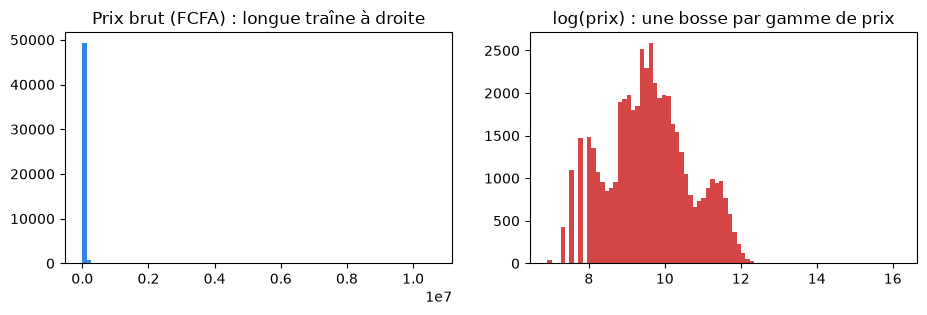

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(prix, bins=80, color="#2E86DE")
axes[0].set_title("Prix brut (FCFA) : longue traîne à droite")
axes[1].hist(log_prix, bins=80, color="#D64545")
axes[1].set_title("log(prix) : une bosse par gamme de prix");

### Au-delà d'une colonne : Mahalanobis (slide 24)

Chaque valeur peut être normale, et la combinaison aberrante. La distance de Mahalanobis mesure l'écart au centre en tenant compte des corrélations.

In [37]:
X = np.log(df[["prix_unitaire_fcfa", "poids_kg"]].astype(float).dropna()).to_numpy()
ecart = X - X.mean(axis=0)
m2 = np.einsum("ij,jk,ik->i", ecart, np.linalg.inv(np.cov(X, rowvar=False)), ecart)
int((m2 > 13.82).sum())

211

211 lignes au-delà du quantile 99,9 % d'un χ² à 2 degrés de liberté (13,82). Isolation Forest, LOF ou DBSCAN (scikit-learn) prolongent cette idée.

### Que faire d'une valeur aberrante ? (slide 25)

Corriger si l'on sait, neutraliser si l'on ne sait pas, garder et signaler si c'est réel. Les 6 décisions du cours, dans l'ordre :

In [38]:
def etape_aberrantes(df, journal, mode="regles"):
    df = df.copy()
    if mode == "aucune":
        return df
    if mode == "iqr_suppression":
        m = outlier_iqr(df["prix_unitaire_fcfa"].astype(float))
        journal.tracer("aberrantes", "prix hors bornes de Tukey (IQR sur le prix brut)", "prix_unitaire_fcfa", m, "supprimer la ligne")
        return df[~m].reset_index(drop=True)
    m = (df["quantite"] < 1) & df["statut"].ne("retournée")
    journal.tracer("aberrantes", "quantité < 1 sur une commande non retournée", "quantite, montant_fcfa", m, "corriger le signe")
    df.loc[m, ["quantite", "montant_fcfa"]] = df.loc[m, ["quantite", "montant_fcfa"]].abs()
    attendu = df["quantite"] * df["prix_unitaire_fcfa"]
    m = (df["montant_fcfa"].abs() - attendu.abs()).abs() > 0.3 * attendu.abs()
    journal.tracer("aberrantes", "montant ≠ quantité × prix", "prix_unitaire_fcfa", m, "prix = montant ÷ quantité")
    df.loc[m, "prix_unitaire_fcfa"] = (df.loc[m, "montant_fcfa"].abs() // df.loc[m, "quantite"]).astype("Int64")
    m = df["poids_kg"] > 200
    journal.tracer("aberrantes", "poids > 200 kg", "poids_kg", m, "÷ 1000 (saisi en grammes)")
    df.loc[m, "poids_kg"] = df.loc[m, "poids_kg"] / 1000
    m = df["note_client"].notna() & ~df["note_client"].isin([1, 2, 3, 4, 5])
    journal.tracer("aberrantes", "note hors 1–5 (0, 30, 40, 50)", "note_client", m, "NaN")
    df.loc[m, "note_client"] = np.nan
    delai_j = (df["date_livraison"] - df["date_commande"]).dt.total_seconds() / 86400
    m = hors_plage(delai_j, 0, 30)
    journal.tracer("aberrantes", "livraison avant la commande ou en 1900", "date_livraison", m, "NaT")
    df.loc[m, "date_livraison"] = pd.NaT
    m = df["quantite"] >= 50
    journal.tracer("aberrantes", "quantité ≥ 50 (revendeur ou saisie ?)", "quantite", m, "garder + drapeau gros_volume")
    df["gros_volume"] = m
    return df


df = etape_aberrantes(df, journal)
suivi.point("4 · aberrantes traitées", df)

📊 Point « 4 · aberrantes traitées » · tests qualité 8 / 8 · volumétrie ✅


,début · 0 · brut,précédent · 3 · doublons traités,maintenant · 4 · aberrantes traitées,écart / précédent
Lignes,50 312,50 000,50 000,=
Commandes livrées,40 036,41 071,41 071,=
Chiffre d'affaires,"1 856,8 M FCFA","1 910,4 M FCFA","1 918,8 M FCFA","+0,4 %"
Panier moyen,46 378 FCFA,46 516 FCFA,46 719 FCFA,"+0,4 %"
Prix unitaire moyen,incalculable,29 117 FCFA,26 280 FCFA,"−9,7 %"
Clients actifs,17 198,17 379,17 379,=
Clients comptés par téléphone,24 276,17 117,17 117,=
Taux de réachat,"68,9 %","69,9 %","69,9 %",=
Rétention de la semaine 1,incalculable,"79,9 %","79,9 %",=
Note moyenne,"4,16 / 5","4,16 / 5","4,23 / 5","+1,7 %"


Aucune ligne supprimée, et les 8 tests passent.
- Le prix moyen baisse de 9,7 % (29 117 → 26 280 FCFA) : 76 prix faux sur 50 000 suffisaient à le gonfler, car la moyenne n'est pas robuste.
- Le délai moyen redevient plausible : 2,40 jours.
- La note moyenne passe de 4,16 à 4,23 : les notes 0, 30, 40 et 50 sont neutralisées.

Le mode `"iqr_suppression"` servira en partie 7 à montrer ce qu'il ne faut pas faire. 💬 Débat (slide 25) : « Pour entraîner un modèle anti-fraude, je supprime toutes les commandes hors des bornes de Tukey. Bonne idée ? »

## 5. Valeurs manquantes (slides 26 à 30)

Avant de combler un trou, on se demande pourquoi il est là.

### Les visages du manquant (slide 26)

`isna()` ne voit que les manquants qui disent leur nom.

In [39]:
pd.Series({
    "note_client = 0":     (brut["note_client"] == 0).sum(),
    "date_livraison 1900": brut["date_livraison"].str.startswith("1900", na=False).sum(),
    "téléphone tronqué":   brut["telephone"].str.fullmatch(r"\d{1,3}", na=False).sum(),
})

note_client = 0        683
date_livraison 1900     53
téléphone tronqué      478
dtype: int64

683 notes à 0 (« pas de note » dans l'ancienne application), 53 dates bidon, 478 téléphones tronqués : tous déguisés en vraies valeurs. Les deux premiers ont déjà été neutralisés par les règles de la partie 4.

### MCAR, MAR ou MNAR ? (slide 27)

In [40]:
pd.crosstab(df["moyen_paiement"], df["email"].isna(), normalize="index").round(2)

email,False,True
moyen_paiement,,
Carte bancaire,0.91,0.09
Mobile Money,0.91,0.09
Paiement à la livraison,0.54,0.46


In [41]:
df.groupby(df["telephone"].isna())["montant_fcfa"].median()

telephone
False    20000.0
True     21000.0
Name: montant_fcfa, dtype: float64

In [42]:
mode = df["categorie"] == "Mode"
print("poids vide en Mode :", round(df.loc[mode, "poids_kg"].isna().mean() * 100, 1), "% · ailleurs :",
      round(df.loc[~mode, "poids_kg"].isna().mean() * 100, 1), "%")

poids vide en Mode : 7.4 % · ailleurs : 1.5 %


- **Téléphone : MCAR.** Le montant médian est presque le même avec ou sans téléphone (20 000 contre 21 000 FCFA).
- **E-mail : MAR.** 46 % d'e-mails vides en paiement à la livraison, contre 9 % sinon : le manque dépend d'une colonne observée.
- **Poids : MAR.** 7,4 % de vides en « Mode », 1,5 % ailleurs.
- **Note : MNAR ?** Les mécontents notent moins. Cela ne se voit pas dans les données seules…

… sauf ici, où l'on dispose d'un **oracle** : la vraie note de chaque commande livrée. Impossible dans la vraie vie, il sert à **mesurer** le biais.

In [43]:
oracle = pd.read_csv(ORACLE, dtype={"commande_id": str})
fusion = df.merge(oracle, on="commande_id", how="left", validate="one_to_one")
livrees = fusion["statut"].isin(["livrée", "retournée"])
pd.DataFrame({
    "note moyenne": [fusion.loc[livrees, "note_vraie"].mean(), fusion.loc[livrees, "note_client"].mean()],
    "notes ≤ 2 (%)": [fusion.loc[livrees, "note_vraie"].le(2).mean() * 100,
                      fusion.loc[livrees, "note_client"].dropna().le(2).mean() * 100],
}, index=["réalité (oracle)", "observé"]).round(2)

,note moyenne,notes ≤ 2 (%)
réalité (oracle),4.03,12.05
observé,4.23,6.74


💬 La note observée (4,23) surestime la réalité (4,03), et les insatisfaits sont presque deux fois plus nombreux qu'on ne le voit (12,1 % contre 6,7 %). Aucune imputation ne corrige ce biais : on calculerait à partir des notes des satisfaits. On le **dit**, on garde les trous, et on mesure autrement (relance des clients qui n'ont pas noté).

### L'arbre de décision (slides 28 et 29)

Quatre questions, dans l'ordre, et la plupart des trous se règlent sans imputer :
1. `date_livraison` vide d'une commande annulée ou en cours : **structurel**, on laisse vide ;
2. `code_promo` vide : l'absence a un sens, « aucun » ;
3. `email` vide : donnée personnelle, on n'invente rien, on ajoute un indicateur `a_email` ;
4. `poids_kg` vide (MAR selon la catégorie) : médiane de la catégorie, avec un indicateur `poids_impute` ;
5. `note_client` vide (MNAR) : on laisse vide et on signale le biais.

Les modes `"dropna"`, `"zero"` et `"moyenne"` serviront en partie 7.

In [44]:
def etape_manquants(df, journal, mode="raisonne"):
    df = df.copy()
    if mode == "aucune":
        return df
    if mode == "dropna":
        m = df.isna().any(axis=1)
        journal.tracer("manquants", "au moins une case vide", "toutes", m, "supprimer la ligne (dropna global)")
        return df.dropna().reset_index(drop=True)
    journal.tracer("manquants", "date_livraison vide (annulée, en cours)", "date_livraison",
                   df["date_livraison"].isna() & df["statut"].isin(["annulée", "en cours"]), "laisser vide (structurel)")
    m = df["code_promo"].isna()
    journal.tracer("manquants", "code_promo vide", "code_promo", m, "« aucun » (pas de promotion)")
    df["code_promo"] = df["code_promo"].fillna("aucun")
    df["a_email"] = df["email"].notna()
    journal.tracer("manquants", "e-mail vide", "email", ~df["a_email"], "laisser vide + indicateur a_email")
    if mode in ("zero", "moyenne"):
        for col in ["poids_kg", "note_client"]:
            m = df[col].isna()
            valeur = 0 if mode == "zero" else df[col].mean()
            journal.tracer("manquants", f"{col} vide", col, m, "remplacer par 0" if mode == "zero" else "remplacer par la moyenne globale")
            df[col] = df[col].fillna(valeur)
        return df
    m = df["poids_kg"].isna()
    df["poids_impute"] = m
    df["poids_kg"] = df["poids_kg"].fillna(df.groupby("categorie", observed=True)["poids_kg"].transform("median"))
    journal.tracer("manquants", "poids vide (MAR selon la catégorie)", "poids_kg", m, "médiane par catégorie + indicateur")
    livrees = df["statut"].isin(["livrée", "retournée"])
    journal.tracer("manquants", "note vide sur commande livrée (MNAR)", "note_client",
                   df["note_client"].isna() & livrees, "laisser vide + signaler le biais")
    return df


df_avant = df
df = etape_manquants(df, journal)
suivi.point("5 · manquants traités", df)

📊 Point « 5 · manquants traités » · tests qualité 8 / 8 · volumétrie ✅


,début · 0 · brut,précédent · 4 · aberrantes traitées,maintenant · 5 · manquants traités,écart / précédent
Lignes,50 312,50 000,50 000,=
Commandes livrées,40 036,41 071,41 071,=
Chiffre d'affaires,"1 856,8 M FCFA","1 918,8 M FCFA","1 918,8 M FCFA",=
Panier moyen,46 378 FCFA,46 719 FCFA,46 719 FCFA,=
Prix unitaire moyen,incalculable,26 280 FCFA,26 280 FCFA,=
Clients actifs,17 198,17 379,17 379,=
Clients comptés par téléphone,24 276,17 117,17 117,=
Taux de réachat,"68,9 %","69,9 %","69,9 %",=
Rétention de la semaine 1,incalculable,"79,9 %","79,9 %",=
Note moyenne,"4,16 / 5","4,23 / 5","4,23 / 5",=


💬 Aucun indicateur ne bouge par rapport au point 4 : le traitement raisonné **n'invente aucun chiffre**. Il remplit ce qui a un sens et laisse vides les trous qui doivent le rester.

### Imputer sans tricher (slide 30)

Pour un modèle de machine learning, on impute quand même, mais sans fuite : on sépare d'abord entraînement et test, on apprend les médianes sur l'entraînement **seulement**, puis on les applique au test.

In [45]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

X = df_avant[["poids_kg", "note_client", "quantite"]].astype(float)
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)
imp = SimpleImputer(strategy="median", add_indicator=True)
X_train = imp.fit_transform(X_train)
X_test = imp.transform(X_test)
print("médianes apprises :", imp.statistics_, "· colonnes après imputation :", X_train.shape[1])

médianes apprises : [0.96 4.   1.  ] · colonnes après imputation : 5


`add_indicator=True` ajoute une colonne « était manquant » pour le poids et la note. En pratique, on place l'imputeur dans un `Pipeline` scikit-learn avec le modèle : la validation croisée ne peut plus tricher.

### La cascade du nettoyage

Les indicateurs et les tests, d'un point d'étape à l'autre :

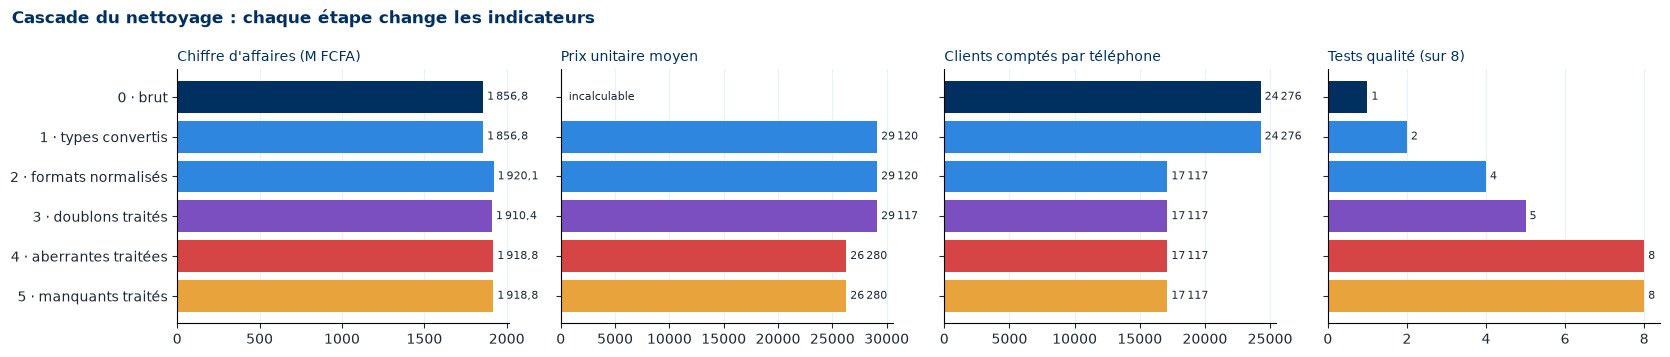

In [46]:
from tp_nettoyage.graphiques import tracer_progression

fig = tracer_progression(suivi, ["ca_fcfa", "prix_moyen_fcfa", "clients_par_telephone", "tests_qualite"])

## 6. Prouver la qualité et exporter (slides 31 à 33)

On ne dit pas « la donnée est propre » : on le prouve, à chaque chargement. On ajoute aux 8 tests du cours un **test de volumétrie** : au moins 95 % des 50 000 commandes attendues.

In [47]:
STATUTS_OK = ["livrée", "annulée", "en cours", "retournée"]
TESTS = {
    "commande_id unique":        lambda d: d["commande_id"].is_unique,
    "clés jamais vides":         lambda d: d[["commande_id", "date_commande", "montant_fcfa"]].notna().all().all(),
    "statut connu":              lambda d: d["statut"].isin(STATUTS_OK).all(),
    "ville du référentiel":      lambda d: d["ville"].dropna().isin(set(VILLES.values())).all(),
    "note entre 1 et 5":         lambda d: d["note_client"].dropna().between(1, 5).all(),
    "livraison après commande":  lambda d: not (d["date_livraison"] < d["date_commande"]).any(),
    "montant = quantité × prix": lambda d: ((d["montant_fcfa"].abs() - d["quantite"] * d["prix_unitaire_fcfa"]).abs()
                                           <= 0.3 * d["quantite"] * d["prix_unitaire_fcfa"]).all(),
    "commandes de septembre":    lambda d: d["date_commande"].dropna().between(DEBUT, FIN, inclusive="left").all(),
    "volumétrie (≥ 95 % des 50 000 commandes)": lambda d: d["commande_id"].nunique() >= 0.95 * 50_000,
}


def verifier(d):
    resultats = pd.Series({nom: bool(test(d)) for nom, test in TESTS.items()})
    assert resultats.all(), f"Tests en échec : {list(resultats[~resultats].index)}"
    return resultats


verifier(df)

commande_id unique                          True
clés jamais vides                           True
statut connu                                True
ville du référentiel                        True
note entre 1 et 5                           True
livraison après commande                    True
montant = quantité × prix                   True
commandes de septembre                      True
volumétrie (≥ 95 % des 50 000 commandes)    True
dtype: bool

Tout passe. Un test qui échoue doit **arrêter** le pipeline (`assert`) au lieu de publier une donnée fausse. 💬 Lequel de ces tests aurait attrapé le casque à 4 500 000 FCFA ? (« montant = quantité × prix »)

### Le journal (slide 32)

Il répond à la question qu'on vous posera dans six mois : « pourquoi 50 000 lignes et pas 50 312 ? ».

In [48]:
journal.table()

,étape,règle,colonne,lignes,décision
0,types,"prix stocké en texte (espaces, « FCFA »)",prix_unitaire_fcfa,9101,convertir en Int64 (\D retiré)
1,types,poids avec virgule décimale,poids_kg,2383,convertir en float64
2,types,date au format américain mm/jj,date_commande,545,relire en mm/jj (fenêtre de septembre)
3,types,villes hors référentiel,ville,7555,ramener au référentiel
4,types,paiements hors référentiel,moyen_paiement,6066,ramener au référentiel
5,types,statuts hors référentiel,statut,1511,ramener au référentiel
6,types,catégorie mal encodée (« TÃ©lÃ©phonie »),categorie,351,encode cp1252 / decode utf-8
7,types,téléphone hors format 01XXXXXXXX,telephone,12591,reformater
8,types,"téléphone invalide (« 97 », étranger, 0000000000)",telephone,967,NaN
9,types,e-mail invalide,email,221,NaN


### Exporter : Parquet contre CSV (slide 33)

In [49]:
df.to_parquet(SCENARIOS_DIR / "1_recommande.parquet", index=False)
df.to_csv(SCENARIOS_DIR / "1_recommande.csv", index=False)
journal.exporter(RAPPORTS_DIR / "journal_nettoyage.csv")
suivi.exporter(RAPPORTS_DIR / "progression_kpis.csv")

pd.DataFrame({
    "Parquet": pd.read_parquet(SCENARIOS_DIR / "1_recommande.parquet").dtypes.astype(str),
    "CSV": pd.read_csv(SCENARIOS_DIR / "1_recommande.csv").dtypes.astype(str),
})

,Parquet,CSV
commande_id,str,str
date_commande,"datetime64[us, Africa/Porto-Novo]",str
client_id,str,str
telephone,str,float64
email,str,str
ville,category,str
categorie,category,str
quantite,int64,int64
prix_unitaire_fcfa,Int64,int64
montant_fcfa,int64,int64


Le Parquet garde tout : dates avec fuseau, `category`, `Int64`, booléens. Le CSV perd tout ce qu'on vient de corriger, jusqu'au zéro des téléphones (redevenus des `float64`).

## 7. Comparer les décisions

Nettoyer, c'est décider. On range toutes les étapes dans une seule fonction : chaque option correspond à une décision.

In [50]:
def nettoyer(brut, *, formats=True, doublons=True, aberrantes="regles", manquants="raisonne", fuseau=TZ):
    j = Journal()
    df = etape_types(brut, j, fuseau)
    if formats:
        df = etape_formats(df, j)
    if doublons:
        df = etape_doublons(df, j)
    df = etape_aberrantes(df, j, aberrantes)
    return etape_manquants(df, j, manquants)


nettoyer(brut).equals(df)

True

Avec les options par défaut, on retrouve exactement le résultat de la partie 6. On produit maintenant **8 versions nettoyées du même fichier**, une par jeu de décisions :

In [51]:
from tp_nettoyage.scenarios import LIBELLES_SCENARIOS, SCENARIOS, harmoniser

pd.DataFrame({"scénario": LIBELLES_SCENARIOS, "options de nettoyer": {k: str(v) for k, v in SCENARIOS.items()}})

,scénario,options de nettoyer
0_brut_type,"Brut, types convertis","{'formats': False, 'doublons': False, 'aberran..."
1_recommande,Recommandé (le cours),{}
2_doublons_gardes,Doublons gardés,{'doublons': False}
3_aberrantes_iqr,Aberrantes supprimées à l'IQR,{'aberrantes': 'iqr_suppression'}
4_manquants_dropna,dropna() global,{'manquants': 'dropna'}
5_manquants_zero,NaN remplacés par 0,{'manquants': 'zero'}
6_fuseau_utc,Dates laissées en UTC,{'fuseau': 'UTC'}
7_imputation_moyenne,Imputation par la moyenne,{'manquants': 'moyenne'}


In [52]:
from tp_nettoyage.qualite import kpis_et_tests

frames, lignes = {}, {}
for nom, options in SCENARIOS.items():
    d = nettoyer(brut, **options)
    d.to_parquet(SCENARIOS_DIR / f"{nom}.parquet", index=False)
    frames[nom] = d
    lignes[nom] = kpis_et_tests(d)
harmoniser(frames).to_parquet(SCENARIOS_DIR / "tous_les_scenarios.parquet", index=False)
kpis = pd.DataFrame.from_dict(lignes, orient="index")
kpis.to_csv(RAPPORTS_DIR / "kpis_scenarios.csv")

In [53]:
from tp_nettoyage.kpis import tableau_lisible

tableau = tableau_lisible(kpis, ["lignes", "ca_fcfa", "prix_moyen_fcfa", "clients_par_telephone", "taux_reachat_pct",
                                 "note_moyenne", "part_insatisfaits_pct", "part_ca_telephonie_pct", "meilleur_jour"])
tableau["tests (sur 8)"] = kpis["tests_qualite"]
tableau["volumétrie"] = kpis["volumetrie"].map({True: "✅", False: "❌"})
tableau.index = [LIBELLES_SCENARIOS[n] for n in tableau.index]
tableau

,Lignes,Chiffre d'affaires,Prix unitaire moyen,Clients comptés par téléphone,Taux de réachat,Note moyenne,Clients insatisfaits,Part du CA en Téléphonie,Meilleur jour,tests (sur 8),volumétrie
"Brut, types convertis",50 312,"1 856,8 M FCFA",29 120 FCFA,24 276,"68,9 %","4,16 / 5","8,7 %","49,8 %",22 sept. 2026,2,✅
Recommandé (le cours),50 000,"1 918,8 M FCFA",26 280 FCFA,17 117,"69,9 %","4,23 / 5","6,7 %","50,6 %",22 sept. 2026,8,✅
Doublons gardés,50 312,"1 928,4 M FCFA",26 300 FCFA,17 117,"70,1 %","4,23 / 5","6,7 %","50,6 %",22 sept. 2026,7,✅
Aberrantes supprimées à l'IQR,43 793,"1 039,9 M FCFA",16 096 FCFA,16 337,"64,5 %","4,16 / 5","8,8 %","10,6 %",22 sept. 2026,5,❌
dropna() global,1 956,"90,9 M FCFA",26 401 FCFA,1 815,"3,9 %","4,22 / 5","6,9 %","52,4 %",2 sept. 2026,8,❌
NaN remplacés par 0,50 000,"1 918,8 M FCFA",26 280 FCFA,17 117,"69,9 %","2,62 / 5","42,2 %","50,6 %",22 sept. 2026,7,✅
Dates laissées en UTC,50 000,"1 918,8 M FCFA",26 280 FCFA,17 117,"69,9 %","4,23 / 5","6,7 %","50,6 %",1er sept. 2026,8,✅
Imputation par la moyenne,50 000,"1 918,8 M FCFA",26 280 FCFA,17 117,"69,9 %","4,23 / 5","4,2 %","50,6 %",22 sept. 2026,8,✅


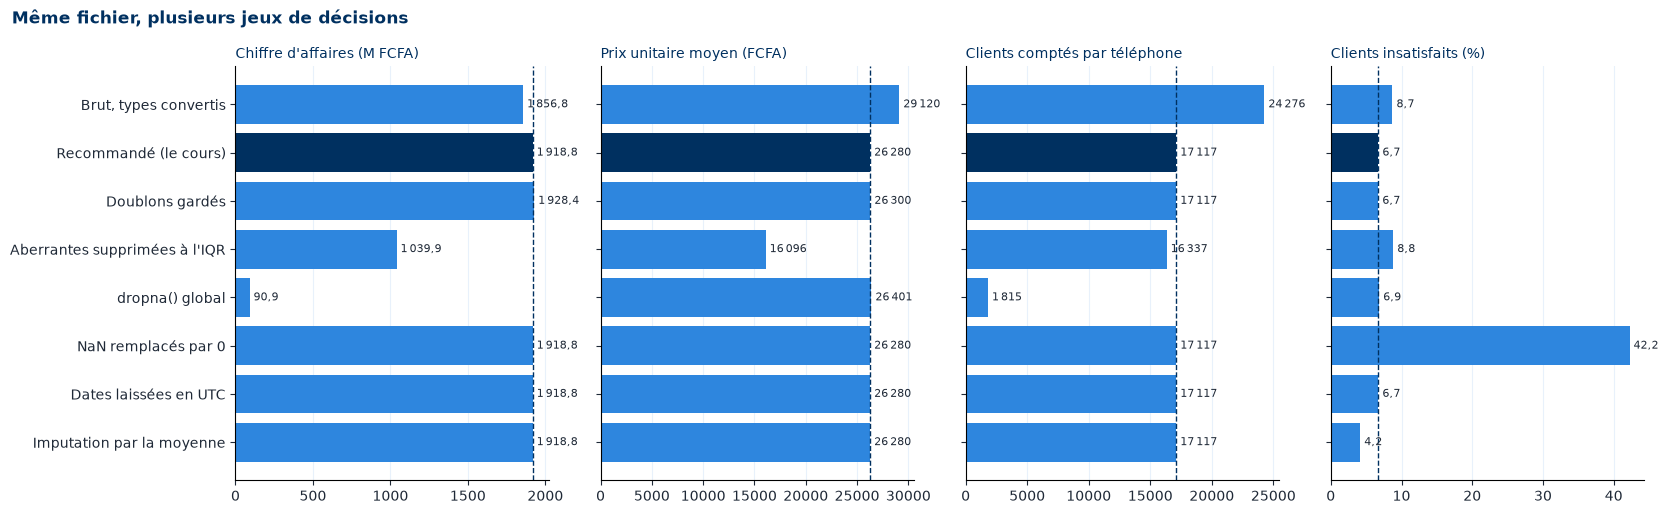

In [54]:
from tp_nettoyage.graphiques import tracer_scenarios

fig = tracer_scenarios(kpis, ["ca_fcfa", "prix_moyen_fcfa", "clients_par_telephone", "part_insatisfaits_pct"])

💬 Même fichier, mêmes données : quelle histoire chaque scénario permet-il de raconter à la direction ?

| Scénario | Ce qui change (par rapport au recommandé) | La phrase trompeuse |
|---|---|---|
| Brut, types convertis | 24 276 clients au lieu de 17 117 (+41,8 %) ; Mobile Money 48,0 % au lieu de 54,7 % ; Cotonou 38,6 % du CA au lieu de 45,2 % ; délai moyen −55,4 jours | « Nous avons 24 000 clients et Cotonou recule. » |
| Doublons gardés | CA 1 928,4 M FCFA au lieu de 1 918,8 : 9,6 M FCFA comptés deux fois ; le test d'unicité échoue | « Septembre a rapporté 1 928,4 M FCFA. » |
| Aberrantes supprimées à l'IQR | CA 1 039,9 M FCFA (−45,8 %) ; Téléphonie 10,6 % du CA au lieu de 50,6 % ; prix moyen 16 096 FCFA (−38,8 %) | « La Téléphonie s'effondre. » |
| `dropna()` global | 1 956 lignes sur 50 000 ; CA 90,9 M FCFA (−95,3 %) ; réachat 3,9 % au lieu de 69,9 % ; plus aucune annulation. Les 8 tests passent : seule la volumétrie refuse ce fichier | « Plus aucune commande annulée en septembre. » |
| NaN remplacés par 0 | note moyenne 2,62 au lieu de 4,23 ; 42,2 % d'insatisfaits au lieu de 6,7 % | « Quatre clients sur dix sont mécontents. » |
| Dates laissées en UTC | meilleur jour le 1er septembre (68,4 M FCFA) au lieu du 22 (68,9 M FCFA) | « Le record du mois a eu lieu le 1er septembre. » |
| Imputation par la moyenne | note inchangée (4,23), mais 4,2 % d'insatisfaits au lieu de 6,7 % ; la vérité (oracle) : 4,03 et 12,1 % | imputer ne corrige pas un biais MNAR, et la moyenne dilue les mécontents |

### Le tableau de bord

Dans un **second terminal**, à la racine du dépôt :

```bash
uv run streamlit run dashboard/app.py
```

Il relit `output/scenarios/tous_les_scenarios.parquet` et `output/`. Cinq onglets : **Vue d'ensemble** (les indicateurs de chaque scénario et leur écart au recommandé), **Cascade du nettoyage** (les points 📊), **Zoom** (CA par ville, par catégorie, par jour, distribution des prix), **Raconter** (les phrases trompeuses, calculées) et **Journal**.

## À retenir

1. Le brut est sacré, tout est en code, chaque décision est tracée au journal.
2. Regarder avant de corriger : `info()`, `describe()`, `value_counts()`, `profil()`.
3. Typer explicitement, convertir avec `errors="coerce"`, puis **compter** ce qui est perdu.
4. Normaliser avant de dédoublonner, puis prouver l'unicité de la clé.
5. Une valeur aberrante est une question : règle métier d'abord, IQR ou MAD sur le log et par groupe ensuite, drapeau toujours.
6. Comprendre **pourquoi** c'est manquant avant d'imputer, et ne jamais laisser fuir le test.
7. Prouver la qualité par des tests, volumétrie comprise : un `dropna()` peut passer 8 tests sur 8.
8. Chaque décision de nettoyage change l'histoire racontée à la direction : on la justifie, chiffres à l'appui.